# LIFTS: Case 1 linear state-space model with 50% MCAR missingness

This notebook is a complete, reproducible example for `lifts==0.1.0`. It:

1. simulates Case 1, a linear latent state-space model;
2. independently hides each value with probability 0.5 (MCAR);
3. trains `LIFTSImputer`;
4. evaluates probabilistic imputation at the missing entries;
5. evaluates the model's in-sample forecasts over the complete time grid; and
6. visualizes the first eight features of one test trajectory.

> **Terminology:** the package argument is `obs_rate`, not `missing_rate`. Therefore a 50% missing rate is passed as `obs_rate = 1 - 0.5 = 0.5`. The realized rate is close to, but not exactly, 50% because MCAR masks are Bernoulli draws.

> **Forecasting scope:** `forecast_samples` below is *in-sample reconstruction/forecasting* on the same `T` time points, conditional on the partially observed sequence. It is not an out-of-sample future-horizon forecast.

## 1. Setup

Download and extract this repository. In a terminal, change to the repository root and install the package and notebook dependencies with `python -m pip install -e ".[notebook]"`. Then launch JupyterLab from the repository root with `jupyter lab` and open this notebook.

In [1]:
import time

import numpy as np
import torch

from lifts import LIFTSImputer, make_case1_dataset, plot_probabilistic_imputation
from modules.evaluations import evaluate_baseline_imputation

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__}")
print(f"Device:  {device}")

PyTorch: 2.6.0+cu124
Device:  cuda


## 2. Generate Case 1 data

Case 1 uses a stable latent VAR(1) process and a linear observation equation:

$$z_t = \Phi z_{t-1} + \varepsilon_t, \qquad x_t = Fz_t + \eta_t.$$

The arrays follow the package convention `(N, p, T)`. `mask == 1` means observed and `mask == 0` means missing.

In [2]:
N_TRAIN = 200
N_TEST = 50
P = 20
D = 5
T = 48
MISSING_RATE = 0.5
OBS_RATE = 1.0 - MISSING_RATE

data = make_case1_dataset(
    num_sample_train=N_TRAIN,
    num_sample_test=N_TEST,
    p=P,
    d=D,
    T=T,
    obs_rate=OBS_RATE,
    mm="mcar",
    seed=SEED,
)

X_train = data["X_train"]
mask_train = data["mask_train"]
X_test = data["X_test"]
mask_test = data["mask_test"]
X_test_full = data["X_test_full"]

assert X_train.shape == (N_TRAIN, P, T)
assert X_test.shape == (N_TEST, P, T)
assert np.isnan(X_train[mask_train == 0]).all()
assert np.isfinite(X_train[mask_train == 1]).all()

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"Train missing rate: {1.0 - mask_train.mean():.2%}")
print(f"Test missing rate:  {1.0 - mask_test.mean():.2%}")

X_train shape: (200, 20, 48)
X_test shape:  (50, 20, 48)
Train missing rate: 49.97%
Test missing rate:  49.71%


## 3. Fit LIFTS

`fo_type="constant"` matches the MCAR mechanism: the observation probability does not depend on the latent state. The settings below keep the tutorial reasonably quick. For a full experiment, increase `total_loops` (for example to 100) and the number of posterior draws.

In [3]:
N_DRAWS = 50

lifts_imputer = LIFTSImputer(
    p=P,
    T=T,
    d=D,
    obs_rate=OBS_RATE,
    total_loops=20,
    batch_size=64,
    n_samples=N_DRAWS,
    lr=1e-3,
    lambda_selfmask=5.0,
    lambda_enc=0.0,
    drop_rate=0.2,
    fx_type="mlp",
    fo_type="constant",
    device=device,
    seed=SEED,
)

started = time.perf_counter()
lifts_imputer.fit(X_train, mask_train, verbose=False)
print(f"Training completed in {time.perf_counter() - started:.1f} seconds")

✅ [Joint] Using SSM_Filter (causal mask)
✅ [Joint] Using Constant Fo (no informative missingness)
✅ [Joint] Using SSM_Decoder_V2 (Attention+FFN)
✅ [Joint] Using SSM_Smoother_V1


Training completed in 13.2 seconds


## 4. Probabilistic imputation and evaluation

LIFTS returns `N_DRAWS` completed trajectories for every test sample. Imputation is evaluated only where the original MCAR mask is zero.

In [4]:
imp_samples = lifts_imputer.impute_samples(
    X_test,
    mask_test,
    n_samples=N_DRAWS,
    batch_size=5,
    samples_per_forward=10,
)
print(f"Imputation samples: {imp_samples.shape}  # (N, draws, p, T)")

target_mask = 1.0 - mask_test
target_X = X_test_full * target_mask

np.random.seed(SEED)  # deterministic Monte Carlo pairs in the energy score
lifts_imputation_results = evaluate_baseline_imputation(
    imp_samples=imp_samples,
    ground_truth=target_X,
    target_mask=target_mask,
    method_name="LIFTS",
)

Imputation samples: (50, 50, 20, 48)  # (N, draws, p, T)


LIFTS IMPUTATION EVALUATION RESULTS (completed in 2.3s)
Samples: N=50, Imputations=50
Data Shape: p=20, T=48
Eval Rate: 49.7%

>>> Metrics (ES, MAE, CRPS)
Metric       | Raw            | Normalized    
----------------------------------------------
ES           |         0.2799 |         0.5248
MAE          |         0.3773 |         0.7073
CRPS         |         0.3037 |         0.5695

>>> Coverage & CI Width (all alphas)
Alpha    | Coverage     | Target     | CI Width    
---------------------------------------------------
   20%   |       13.0%  |      20%  |       0.1573
   30%   |       19.4%  |      30%  |       0.2394
   40%   |       26.1%  |      40%  |       0.3252
   50%   |       33.0%  |      50%  |       0.4176
   60%   |       39.9%  |      60%  |       0.5206
   70%   |       47.5%  |      70%  |       0.6392
   80%   |       55.9%  |      80%  |       0.7850
   90%   |       65.9%  |      90%  |       0.9927


## 5. In-sample forecasting and evaluation

Unlike `impute_samples`, `forecast_samples` does not replace observed values with their inputs. We therefore evaluate these model-generated trajectories over all entries of the original `T`-step grid.

In [5]:
fore_samples = lifts_imputer.forecast_samples(
    X_test,
    mask_test,
    n_samples=N_DRAWS,
    batch_size=16,
    samples_per_forward=10,
)
print(f"Forecast samples: {fore_samples.shape}  # (N, draws, p, T)")

all_eval_mask = np.ones_like(mask_test, dtype=np.float32)
np.random.seed(SEED)
lifts_forecast_results = evaluate_baseline_imputation(
    imp_samples=fore_samples,
    ground_truth=X_test_full,
    target_mask=all_eval_mask,
    method_name="LIFTS in-sample forecasting (all points)",
)

Forecast samples: (50, 50, 20, 48)  # (N, draws, p, T)


LIFTS IN-SAMPLE FORECASTING (ALL POINTS) IMPUTATION EVALUATION RESULTS (completed in 3.3s)
Samples: N=50, Imputations=50
Data Shape: p=20, T=48
Eval Rate: 100.0%

>>> Metrics (ES, MAE, CRPS)
Metric       | Raw            | Normalized    
----------------------------------------------
ES           |         0.2784 |         0.5247
MAE          |         0.3959 |         0.7460
CRPS         |         0.3066 |         0.5778

>>> Coverage & CI Width (all alphas)
Alpha    | Coverage     | Target     | CI Width    
---------------------------------------------------
   20%   |       20.7%  |      20%  |       0.2656
   30%   |       30.8%  |      30%  |       0.4036
   40%   |       40.9%  |      40%  |       0.5479
   50%   |       50.9%  |      50%  |       0.7021
   60%   |       60.6%  |      60%  |       0.8715
   70%   |       70.0%  |      70%  |       1.0653
   80%   |       79.0%  |      80%  |       1.3010
   90%   |       87.8%  |      90%  |       1.6287


## 6. Compact metric summary

In [6]:
rows = [
    ("Imputation (missing only)", lifts_imputation_results),
    ("In-sample forecast (all)", lifts_forecast_results),
]

print(f"{'Evaluation':<30} {'MAE':>9} {'RMSE':>9} {'CRPS':>9} {'ES':>9} {'Cov@90%':>10}")
print("-" * 80)
for label, result in rows:
    print(
        f"{label:<30} "
        f"{result['MAE']:>9.4f} {result['RMSE']:>9.4f} "
        f"{result['CRPS']:>9.4f} {result['ES']:>9.4f} "
        f"{result['coverage'][0.9]:>10.2%}"
    )

Evaluation                           MAE      RMSE      CRPS        ES    Cov@90%
--------------------------------------------------------------------------------
Imputation (missing only)         0.3773    0.4871    0.3037    0.2799     65.91%
In-sample forecast (all)          0.3959    0.5129    0.3066    0.2784     87.85%


## 7. Visualize the imputation distribution

The blue band is the 95% posterior interval and the blue line is the posterior median. Red crosses are observed inputs; black circles identify values that were hidden and used as imputation ground truth.

Visualizing test sample 0
  imp_samples: (50, 8, 48)
  ground_truth: (8, 48)
  mask:         (8, 48)


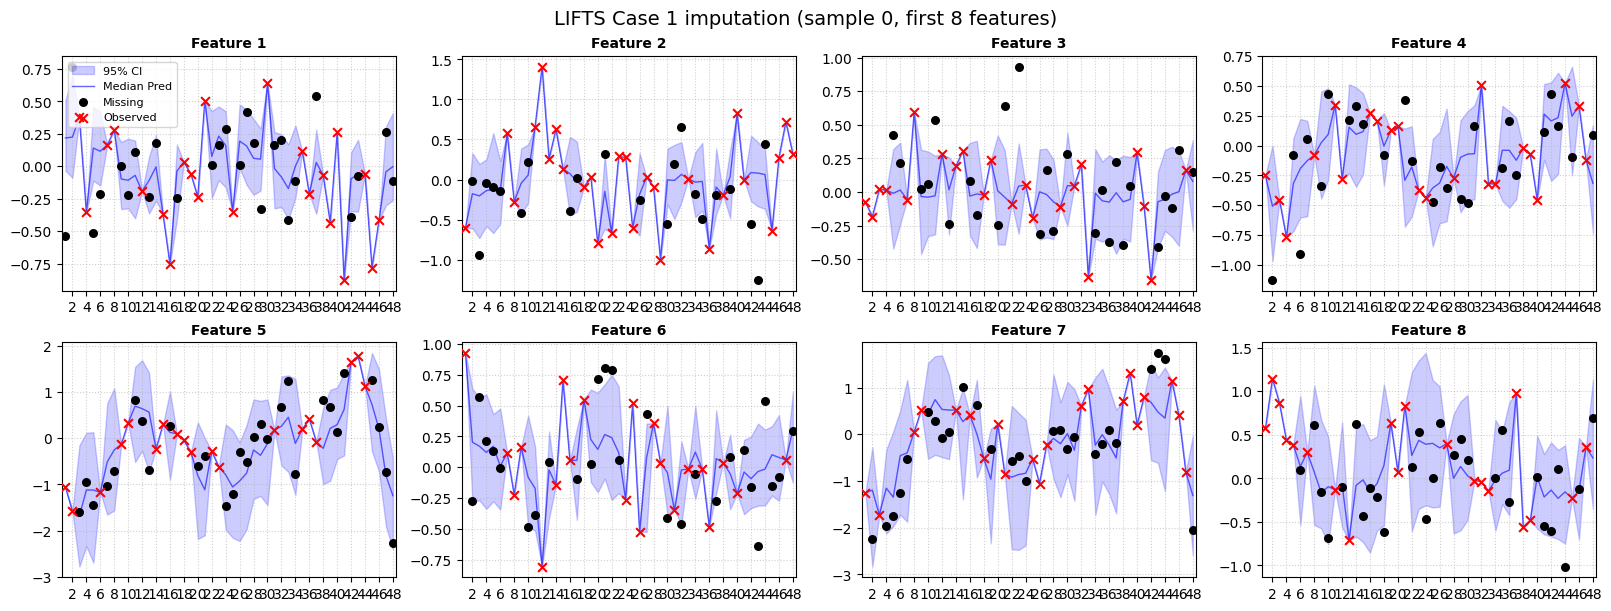

In [7]:
sample_idx_vis = 0
n_features_show = 8

imp_samples_vis = torch.from_numpy(
    imp_samples[sample_idx_vis, :, :n_features_show, :]
).float()
gt_vis = torch.from_numpy(
    X_test_full[sample_idx_vis, :n_features_show, :]
).float()
mask_vis = torch.from_numpy(
    mask_test[sample_idx_vis, :n_features_show, :]
).float()

print(f"Visualizing test sample {sample_idx_vis}")
print(f"  imp_samples: {tuple(imp_samples_vis.shape)}")
print(f"  ground_truth: {tuple(gt_vis.shape)}")
print(f"  mask:         {tuple(mask_vis.shape)}")

plot_probabilistic_imputation(
    imp_samples_vis,
    gt_vis,
    p=n_features_show,
    T=T,
    obs_mask=mask_vis,
    title=(
        f"LIFTS Case 1 imputation (sample {sample_idx_vis}, "
        f"first {n_features_show} features)"
    ),
)